In [1]:
from quantify_core.data.handling import (
    default_datadir,
    get_latest_tuid,
    get_tuids_containing,
    load_dataset,
    locate_experiment_container,
    set_datadir,
)

import numpy as np
import matplotlib.pyplot as plt

In [3]:
set_datadir(default_datadir())

Data will be saved in:
/home/pschaefers/quantify-data


In [4]:
def process_CMAES_data(dataset, population_size, qubit_names=None):
        """
        Processes fidelity data for n qubits based on the given dataset and population size.

        Parameters:
            dataset: An object containing data attributes (e.g., dataset.x0.data, dataset.y0.data, etc.).
            population_size: The size of the population.
            nr_qubits: The number of qubits.

        Returns:
            A dictionary containing mean and population fidelity data for all qubit_names and shared parameters.
        """

        if qubit_names is None:
            if hasattr(dataset, "elements"):
                qubit_names = dataset.elements
            else:
                raise ValueError("No qubit names provided and dataset has no 'elements' attribute.")

        # Extract parameters shared across all qubits
        shared_data = {
            'objective': dataset.y0.data,
        }

        # Initialize dictionary to hold data for each qubit
        fidelity_data = {'shared': shared_data}

        name_to_var = {dataset[var].attrs.get("name"): var for var in dataset.data_vars}
        name_to_coord = {dataset[coord].attrs.get("name"): coord for coord in dataset.coords}

        for qubit in qubit_names:
            # Extract fidelity data for the current qubit
            fidelity_data[qubit] = {
                'freq': dataset[name_to_coord.get(f"frequency_{qubit}")].values,
                'ampl': dataset[name_to_coord.get(f"amplitude_{qubit}")].values,
                'dur': dataset[name_to_coord.get(f"duration_{qubit}")].values,
                'assignfid_av': dataset[name_to_var.get(f"av_assignment_{qubit}")].values,
                'qndpifid': dataset[name_to_var.get(f"qnd_pi_{qubit}")].values,
            }

            # Extract data of the mean
            fidelity_data[qubit]['mean'] = {
                key: fidelity_data[qubit][key][population_size::population_size + 1]
                for key in
                ['freq', 'ampl', 'dur', 'assignfid_av', 'qndpifid']
            }

            # Extract data of the population
            fidelity_data[qubit]['pop'] = {
                key: np.array([
                    fidelity_data[qubit][key][i::population_size + 1]
                    for i in range(population_size)
                ])
                for key in
                ['freq', 'ampl', 'dur', 'assignfid_av', 'qndpifid']
            }

        return fidelity_data

In [5]:
tuids_sum = ["20250819-202711-856-3b5727", "20250819-194830-877-a5b169","20250819-191009-345-ecd152", "20250819-183141-260-4972fb", "20250819-175311-638-06e9a1"]
tuids_product = ["20250819-204634-379-0a75be","20250819-200752-068-30e1a3","20250819-192915-724-060852","20250819-185056-482-07248a","20250819-181232-512-0a4245"]

In [15]:
processed_data = {}
processed_data["sum"] = {}
processed_data["product"] = {}

# name = []
for i in range(len(tuids_sum)):
    name.append(f"data_{i}")

for i in range(len(tuids_sum)):
    data_sum = load_dataset(tuids_sum[i])
    processed_data["sum"][name[i]] = process_CMAES_data(data_sum, 20)

    data_product = load_dataset(tuids_product[i])
    processed_data["product"][name[i]] = process_CMAES_data(data_product, 20)
    

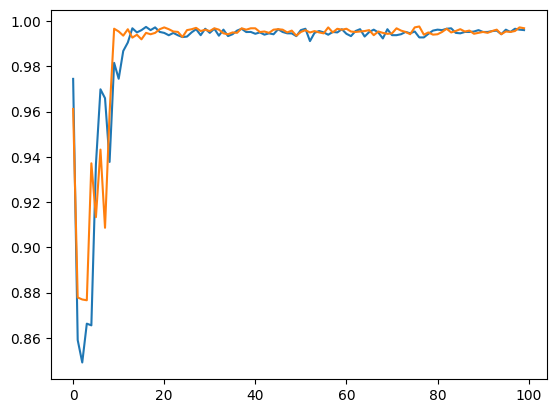

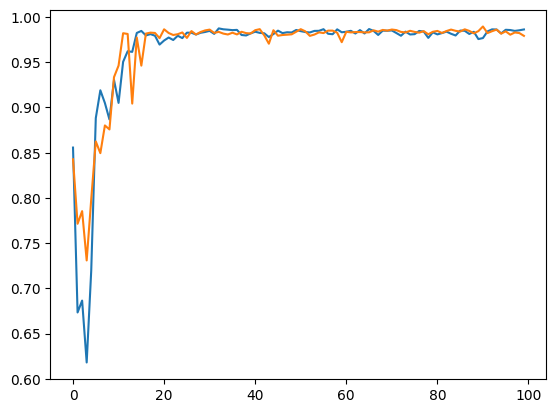

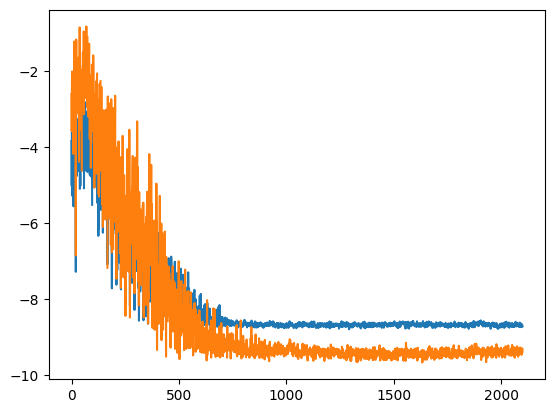

In [33]:
average_evolution_sum_X1 = 0
average_evolution_product_X1 = 0

average_evolution_sum_X2 = 0
average_evolution_product_X2 = 0

qnd_evolution_sum_X1 = 0
qnd_evolution_product_X1 = 0

qnd_evolution_sum_X2 = 0
qnd_evolution_product_X2 = 0

obj_evolution_sum_X1 = 0
obj_evolution_product_X1 = 0

obj_evolution_sum_X2 = 0
obj_evolution_product_X2 = 0

for i in range(len(tuids_sum)):
    average_evolution_sum_X1 += processed_data["sum"][name[i]]["X1"]["mean"]["assignfid_av"]
    average_evolution_sum_X2 += processed_data["sum"][name[i]]["X2"]["mean"]["assignfid_av"]

    average_evolution_product_X1 += processed_data["product"][name[i]]["X1"]["mean"]["assignfid_av"]
    average_evolution_product_X2 += processed_data["product"][name[i]]["X2"]["mean"]["assignfid_av"]

    qnd_evolution_sum_X1 += processed_data["sum"][name[i]]["X1"]["mean"]["qndpifid"]
    qnd_evolution_sum_X2 += processed_data["sum"][name[i]]["X2"]["mean"]["qndpifid"]

    qnd_evolution_product_X1 += processed_data["product"][name[i]]["X1"]["mean"]["qndpifid"]
    qnd_evolution_product_X2 += processed_data["product"][name[i]]["X2"]["mean"]["qndpifid"]

    obj_evolution_sum_X1 += processed_data["sum"][name[i]]["shared"]["objective"]
    obj_evolution_sum_X2 += processed_data["sum"][name[i]]["shared"]["objective"]

    obj_evolution_product_X1 += processed_data["product"][name[i]]["shared"]["objective"]
    obj_evolution_product_X2 += processed_data["product"][name[i]]["shared"]["objective"]

plt.plot(range(100), average_evolution_sum_X1/5)
plt.plot(range(100), average_evolution_product_X1/5)
plt.show()

plt.plot(range(100), qnd_evolution_sum_X1/5)
plt.plot(range(100), qnd_evolution_product_X1/5)
plt.show()

plt.plot(obj_evolution_sum_X1/5)
plt.plot(obj_evolution_product_X1/5)
plt.show()

In [20]:
print(np.mean([np.array([1,2]),np.array([1,2])],axis=0))

[1. 2.]
